In [1]:
%pip install -U microlens_submit
%pip install -U RTModel==3.3
%pip install -U jacscanomaly
%pip install -U microjax
%pip uninstall -U pyAethra
%pip install -U pyAethra

%pip install seaborn


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

Usage:   
  /opt/conda/envs/rges-pit-dc/bin/python -m pip uninstall [options] <package> ...
  /opt/conda/envs/rges-pit-dc/bin/python -m pip uninstall [options] -r <requirements file> ...

no such option: -U
Note: you may need to restart the kernel to use updated packages.

[notice] A new re

In [22]:
# system imports
import os
import glob
import time
import sys
from pathlib import Path
from tqdm import tqdm

# data access imports
from huggingface_hub import hf_hub_download
import pandas as pd
from astropy.coordinates import SkyCoord
import astropy.units as u

# display imports
from IPython.display import HTML

# multiprocessing imports
import multiprocessing as mp
from multiprocessing.pool import ThreadPool

# data challenge imports
import microlens_submit
#import MulensModel
import emcee
#from pyLIMA.pyLIMASS import SourceLensProbabilities
import RTModel

# data analysis/visualization imports
import numpy as np
import matplotlib.pyplot as plt

# detection packages
from pyAethra import load_config, load_and_run
from jacscanomaly import CandidateCriteria, Finder, FinderConfig

root_dir = '/home/mldc-ipacpeople-admin/teams/mldc-ipacpeople/'

In [3]:
import pyAethra
print(pyAethra.__version__)
import jacscanomaly
print(jacscanomaly.__version__)
print(sys.version)
print(np.__version__)

0.1.1
0.5.1
3.11.14 | packaged by conda-forge | (main, Jan 26 2026, 23:48:32) [GCC 14.3.0]
2.4.1


In [4]:
# following extra instructions for data download from https://huggingface.co/datasets/RGES-PIT/MachineLearning
%pip install datasets pandas pyarrow duckdb huggingface_hub

/opt/conda/envs/rges-pit-dc/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
from datasets import load_dataset
import os

os.environ["HF_TOKEN"] = "hf_your_token_here" # will replace before pushing; dear teammates: please don't compromise me

token = os.environ.get("HF_TOKEN")
assert token, "Set HF_TOKEN environment variable first"

# con.execute("""
#     CREATE SECRET hf_token (
#         TYPE HUGGINGFACE,
#         PROVIDER credential_chain
#     );
# """)

dataset_name = "RGES-PIT/MachineLearning"

# Load metadata and epochs tables (which fit easily in RAM)
meta_df = load_dataset(dataset_name, "metadata", split="train", token=token).to_pandas()
epochs_df = load_dataset(dataset_name, "epochs", split="train", token=token).to_pandas()

print(f"Metadata     : {meta_df.shape[0]:,} rows")
print(f"Epochs       : {epochs_df.shape[0]:,} rows")


Metadata     : 377,999 rows
Epochs       : 98,974 rows


In [6]:
import duckdb
from huggingface_hub import HfFileSystem
import os

token = os.environ.get("HF_TOKEN")
con = duckdb.connect()
con.register_filesystem(HfFileSystem(token=token))

obs_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_obs.parquet"
meta_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_meta.parquet"
epoch_p = "hf://datasets/RGES-PIT/MachineLearning/RMDC26_ML_Data_epoch.parquet"

event_id = 3000

# Reconstruct a single event's lightcurve
event_obs = con.execute(f"""
    SELECT 
        o.event_id,
        m.name,
        e.bjd,
        o.filt,
        o.flux_uJy,
        m.tE_helio,
        m.sim_label
    FROM '{obs_p}' o
    JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
    JOIN '{meta_p}' m ON o.event_id = m.event_id
    WHERE o.event_id = {event_id}
    ORDER BY e.bjd
""").df()

print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")
print(f"  {len(event_obs):,} observations")
print(f"  Einstein timescale tE_helio = {abs(event_obs['tE_helio'].iloc[0]):.2f} days")

Event 3000: RMDC26_003000 (RMDC26_1S1L_ML)
  49,488 observations
  Einstein timescale tE_helio = 3.55 days


In [7]:
meta_df_1s2l = meta_df.loc[(meta_df['sim_label']=='RMDC26_1S2L_ML')]
meta_df_1s2l

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,Source_Fe_H,Source2_Mass,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213
18695,RMDC26_306456,306456,RMDC26_1S2L_ML,5.0,88.0,161.0,0.004666,2905.396867,2.463174e+06,12.436439,...,-0.665622,NaN,NaN,NaN,NaN,NaN,True,0.488442,1.219401,0.163966
18696,RMDC26_306472,306472,RMDC26_1S2L_ML,1.0,916.0,442.0,0.008321,1887.063475,2.461828e+06,30.752139,...,0.106405,NaN,NaN,NaN,NaN,NaN,False,0.704850,1.759666,0.236613
18697,RMDC26_306488,306488,RMDC26_1S2L_ML,8.0,877.0,768.0,0.021125,5393.324667,2.462935e+06,49.493615,...,-0.136265,NaN,NaN,NaN,NaN,NaN,False,0.499110,1.246033,0.167547
18698,RMDC26_306504,306504,RMDC26_1S2L_ML,0.0,634.0,123.0,0.009865,2679.048659,2.463146e+06,25.844615,...,-0.064195,NaN,NaN,NaN,NaN,NaN,False,2.999992,7.489517,1.007075
18699,RMDC26_306520,306520,RMDC26_1S2L_ML,7.0,48.0,395.0,0.005591,51081.451737,2.462192e+06,2.685336,...,0.430370,NaN,NaN,NaN,NaN,NaN,True,0.406146,1.013948,0.136340
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
375314,RMDC26_342023,342023,RMDC26_1S2L_ML,1.0,754.0,471.0,0.010119,596.386791,2.463079e+06,13.299357,...,0.414304,NaN,NaN,NaN,NaN,NaN,True,1.328165,3.315781,0.445855
375315,RMDC26_342039,342039,RMDC26_1S2L_ML,4.0,676.0,869.0,0.008407,138023.979042,2.461720e+06,24.371962,...,0.024497,NaN,NaN,NaN,NaN,NaN,True,0.742187,1.852880,0.249147
375316,RMDC26_342055,342055,RMDC26_1S2L_ML,3.0,917.0,4.0,0.000568,123.205793,2.461861e+06,9.028149,...,0.355993,NaN,NaN,NaN,NaN,NaN,False,0.556260,1.388709,0.186732
375317,RMDC26_342071,342071,RMDC26_1S2L_ML,7.0,640.0,282.0,0.081258,70218.204734,2.462782e+06,36.248093,...,-0.222894,NaN,NaN,NaN,NaN,NaN,False,0.357378,0.892198,0.119969


In [8]:
meta_df_1s1l = meta_df.loc[(meta_df['sim_label']=='RMDC26_1S1L_ML')]
meta_df_1s1l

,name,event_id,sim_label,SubRun,Field,EventID,final_weight,ObsGroup_0_chi2,t0lens1,tE_ref,...,Source_Fe_H,Source2_Mass,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213
0,RMDC26_003000,3000,RMDC26_1S1L_ML,0.0,633.0,1936.0,0.012366,66.744210,2.462736e+06,3.585315,...,0.319104,NaN,NaN,NaN,NaN,NaN,False,2.061971,5.147735,0.692188
1,RMDC26_003016,3016,RMDC26_1S1L_ML,0.0,718.0,7002.0,0.021194,13124.511426,2.462735e+06,0.214467,...,0.120387,NaN,NaN,NaN,NaN,NaN,False,0.483870,1.207987,0.162431
2,RMDC26_003032,3032,RMDC26_1S1L_ML,0.0,874.0,572.0,0.016154,3438.811691,2.461841e+06,0.051493,...,-0.556216,NaN,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703
3,RMDC26_003048,3048,RMDC26_1S1L_ML,2.0,0.0,4028.0,0.013090,379.330478,2.461504e+06,14.050508,...,0.080757,NaN,NaN,NaN,NaN,NaN,False,3.180586,7.940372,1.067699
4,RMDC26_003064,3064,RMDC26_1S1L_ML,1.0,21.0,7425.0,0.034964,103.546626,2.461713e+06,36.203618,...,-0.110039,NaN,NaN,NaN,NaN,NaN,True,2.581654,6.445132,0.866642
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
373086,RMDC26_306375,306375,RMDC26_1S1L_ML,1.0,676.0,4437.0,0.012477,26835.710390,2.461653e+06,0.071499,...,0.275095,NaN,NaN,NaN,NaN,NaN,False,0.742187,1.852880,0.249147
373087,RMDC26_306391,306391,RMDC26_1S1L_ML,0.0,598.0,7263.0,0.048676,47962.259643,2.462957e+06,1.468066,...,0.211120,NaN,NaN,NaN,NaN,NaN,False,0.449580,1.122381,0.150921
373088,RMDC26_306407,306407,RMDC26_1S1L_ML,1.0,88.0,9926.0,0.863027,94.722852,2.462837e+06,52.013203,...,-0.446141,NaN,NaN,NaN,NaN,NaN,True,0.488442,1.219401,0.163966
373089,RMDC26_306423,306423,RMDC26_1S1L_ML,1.0,673.0,7090.0,0.014256,437852.475921,2.461505e+06,14.545849,...,-0.449106,NaN,NaN,NaN,NaN,NaN,False,2.590036,6.466057,0.869456


In [9]:
event_ids = np.unique(meta_df_1s2l['event_id'])
print(len(event_ids))

35647


In [10]:
# s_bins = np.concat([np.linspace(0.2, 2, 10), np.linspace(2.5, 6, 8), np.linspace(7, 10, 4)])
# q_bins = np.logspace(-7, -2, 20)
s_bins = np.concat([np.linspace(0.2, 2, 8), np.linspace(2.5, 6, 4), np.linspace(7, 10, 3)])
q_bins = np.logspace(-7, -2, 15)

In [11]:
# bin by Lens_Mass because Planet_s and Planet_q are empty 

# omit events injected off-season
meta_df_1s1l_in_season = meta_df_1s1l.loc[meta_df_1s1l['is_out_of_season']==False]
print(len(meta_df_1s1l), len(meta_df_1s1l_in_season))

# omit events with injected |u0|>3.5 --> peak magnification < 1%, per Paczynski formula
# u0 threshold of 0.1 --> peak magnification of 10%
meta_df_1s1l_in_season_u0 = meta_df_1s1l_in_season.loc[np.abs(meta_df_1s1l_in_season.u0lens1)<=0.1]
print(len(meta_df_1s1l_in_season_u0))

# keep only true FFPs
meta_df_1s1l_in_season_u0_ffp = meta_df_1s1l_in_season_u0.loc[(meta_df_1s1l_in_season_u0.tE_ref <= 2.) & (meta_df_1s1l_in_season_u0.tE_ref >= 0.5)]
print(len(meta_df_1s1l_in_season_u0_ffp))
print(meta_df_1s1l_in_season_u0_ffp.Lens_Mass)

# # groupby q bin and sample 100 or however many events are in that bin, whichever is smaller
# samples_1d = 100
# meta_df_1s1l_sampled = meta_df_1s1l_in_season_u0_ffp.groupby(['q_bin'], observed=False).apply(
#     lambda g: g.sample(n=min(len(g), samples_1d)) if len(g) > 0 else g
# ).reset_index(drop=True)

# print(meta_df_1s1l_sampled.groupby(['q_bin'], observed=False).size())

299466 204517
12007
2478
363       0.073127
629       0.000418
668       0.004093
881       0.002937
1054      0.002650
            ...   
372114    0.000799
372165    0.001119
372587    0.003038
372740    0.000422
372793    0.001704
Name: Lens_Mass, Length: 2478, dtype: float64


In [12]:
# bin by s and q
meta_df_1s2l['s_bin'] = pd.cut(meta_df_1s2l['Planet_s'], bins=s_bins)
meta_df_1s2l['q_bin'] = pd.cut(meta_df_1s2l['Planet_q'], bins=q_bins)

# omit events injected off-season
meta_df_1s2l_in_season = meta_df_1s2l.loc[meta_df_1s2l['is_out_of_season']==False]
print(len(meta_df_1s2l), len(meta_df_1s2l_in_season))

# omit events with injected |u0|>3.5 --> peak magnification < 1%, per Paczynski formula
meta_df_1s2l_in_season_u0 = meta_df_1s2l_in_season.loc[np.abs(meta_df_1s2l_in_season.u0lens1)<=3.5]
print(len(meta_df_1s2l_in_season_u0))

# 2D groupby and sample 100 or however many events are in that 2D bin, whichever is smaller
samples_2d = 100
meta_df_1s2l_sampled = meta_df_1s2l_in_season_u0.groupby(['s_bin', 'q_bin'], observed=False).apply(
    lambda g: g.sample(n=min(len(g), samples_2d)) if len(g) > 0 else g
).reset_index(drop=True)

print(meta_df_1s2l_sampled.groupby(['s_bin', 'q_bin'], observed=False).size())

35647 25147
17898


/tmp/ipykernel_2155/1792137821.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  meta_df_1s2l['s_bin'] = pd.cut(meta_df_1s2l['Planet_s'], bins=s_bins)
/tmp/ipykernel_2155/1792137821.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  meta_df_1s2l['q_bin'] = pd.cut(meta_df_1s2l['Planet_q'], bins=q_bins)


s_bin         q_bin               
(0.2, 0.457]  (1e-07, 2.28e-07]        1
              (2.28e-07, 5.18e-07]     2
              (5.18e-07, 1.18e-06]     3
              (1.18e-06, 2.68e-06]     6
              (2.68e-06, 6.11e-06]     4
                                      ..
(8.5, 10.0]   (0.000164, 0.000373]    34
              (0.000373, 0.000848]    14
              (0.000848, 0.00193]     16
              (0.00193, 0.00439]      10
              (0.00439, 0.01]          3
Length: 196, dtype: int64


/tmp/ipykernel_2155/1792137821.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  meta_df_1s2l_sampled = meta_df_1s2l_in_season_u0.groupby(['s_bin', 'q_bin'], observed=False).apply(


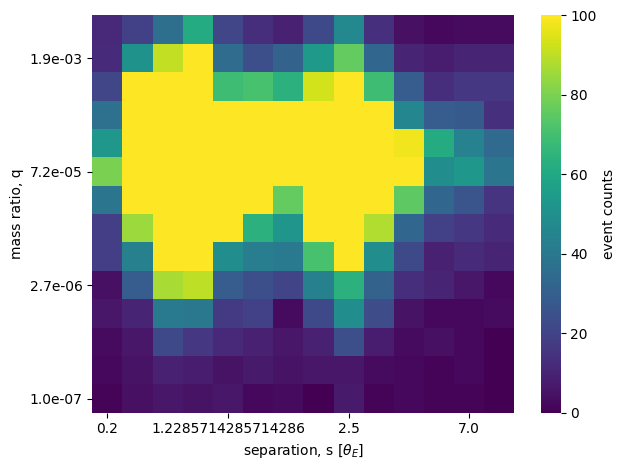

In [13]:
import seaborn as sns

# event counts per s, q bin
heatmap_data = pd.crosstab(meta_df_1s2l_sampled["s_bin"], meta_df_1s2l_sampled["q_bin"]).T

# prep axis labels cause we boutta aesthetize
y_labels = q_bins[:-1]
x_labels = s_bins[:-1]

# plot heatmap
ax = sns.heatmap(
    heatmap_data, annot=False, fmt="d", cmap="viridis", xticklabels=False, yticklabels=False,
    cbar_kws={"label": "event counts"}
)
ax.invert_yaxis() 

# show every 4th tick, and place ticks at center of corresponding cells
x_ticks = np.arange(len(x_labels))[::4] + 0.5
y_ticks = np.arange(len(y_labels))[::4] + 0.5
ax.set_xticks(x_ticks)
ax.set_xticklabels([x_labels[int(i)] for i in np.arange(len(x_labels))[::4]])
ax.set_yticks(y_ticks)
ax.set_yticklabels([f"{y_labels[int(i)]:.1e}" for i in np.arange(len(y_labels))[::4]])

ax.set_xlabel(r"separation, s [$\theta_E$]")
ax.set_ylabel("mass ratio, q")
plt.tight_layout()
plt.savefig(root_dir+'/plots/denominator_1s2l.png')
plt.show()


#### Numerator

In [14]:
kansuke = pd.read_csv(root_dir + '/data/aethra-filtered-results.csv')
kansuke

/tmp/ipykernel_2155/3586196672.py:1: DtypeWarning: Columns (2,7,8,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  kansuke = pd.read_csv(root_dir + '/data/aethra-filtered-results.csv')


,event_id,dataset,display_id,truth_label,truth_scope,truth_label_available,truth_physical_available,variable_type,variant,missing_observations,...,pyaethra_te_fit,pyaethra_chi2_red_pspl,pyaethra_bump_flag,pyaethra_bump_snr,jacscanomaly_available,jacscanomaly_status,jacscanomaly_model,jacscanomaly_label,jacscanomaly_n_candidates,jacscanomaly_best_score
0,3000,RMDC ML,NaN,1S1L,physical,1,1,NaN,NaN,0,...,99.999994,1.000966,1.0,7.097806,1,ok,PSPL,No candidate,0.0,5.456774
1,3001,RMDC ML,NaN,1S1L,physical,1,1,NaN,NaN,0,...,0.435480,0.978810,1.0,10.995008,1,ok,PSPL,No candidate,0.0,5.261667
2,3002,RMDC ML,NaN,1S1L,physical,1,1,NaN,NaN,0,...,10.780581,1.038280,1.0,5.265094,1,ok,PSPL,No candidate,0.0,6.140409
3,3003,RMDC ML,NaN,1S1L,physical,1,1,NaN,NaN,0,...,38.551631,0.992137,1.0,19.186480,1,ok,PSPL,No candidate,0.0,4.347362
4,3004,RMDC ML,NaN,1S1L,physical,1,1,NaN,NaN,0,...,16.734656,0.992668,1.0,3.857099,1,ok,PSPL,No candidate,0.0,4.821533
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
386762,2002366,2371 Events,2371 Events · 2366 · 0_996_928,Planet,physical,1,1,NaN,NaN,0,...,8.384543,1.025635,1.0,1406.983565,1,ok,PSPL,Candidate,1.0,29.870978
386763,2002367,2371 Events,2371 Events · 2367 · 0_996_1283,Planet,physical,1,1,NaN,NaN,0,...,2.900398,1.993942,1.0,441.672771,1,ok,PSPL,Candidate,1.0,1278.381844
386764,2002368,2371 Events,2371 Events · 2368 · 0_996_1648,Planet,physical,1,1,NaN,NaN,0,...,8.294283,0.993832,1.0,2590.938018,1,ok,PSPL,Candidate,1.0,13.660135
386765,2002369,2371 Events,2371 Events · 2369 · 0_996_1994,Planet,physical,1,1,NaN,NaN,0,...,8.929708,0.994630,1.0,821.469131,1,ok,PSPL,No candidate,0.0,5.201461


In [15]:
kansuke_1s2l_sampled = pd.merge(kansuke, meta_df_1s2l_sampled, on='event_id', how='inner')
kansuke_1s2l_sampled

,event_id,dataset,display_id,truth_label,truth_scope,truth_label_available,truth_physical_available,variable_type,variant,missing_observations,...,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213,s_bin,q_bin
0,306467,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703,"(0.971, 1.229]","(0.00193, 0.00439]"
1,306470,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703,"(4.833, 6.0]","(3.16e-05, 7.2e-05]"
2,306479,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.488442,1.219401,0.163966,"(0.457, 0.714]","(6.11e-06, 1.39e-05]"
3,306496,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.311658,0.778058,0.104621,"(2.5, 3.667]","(1.18e-06, 2.68e-06]"
4,306501,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,2.560318,6.391866,0.859480,"(6.0, 7.0]","(1.39e-05, 3.16e-05]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8665,342080,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.556260,1.388709,0.186732,"(2.5, 3.667]","(0.000848, 0.00193]"
8666,342083,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.341376,0.852249,0.114597,"(2.0, 2.5]","(3.16e-05, 7.2e-05]"
8667,342084,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,3.587493,8.956222,1.204295,"(4.833, 6.0]","(7.2e-05, 0.000164]"
8668,342087,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.742187,1.852880,0.249147,"(0.714, 0.971]","(1.39e-05, 3.16e-05]"


In [16]:
numerator = kansuke_1s2l_sampled.loc[(kansuke_1s2l_sampled['pyaethra_label']=='microlensing') & (kansuke_1s2l_sampled['jacscanomaly_best_score']>=10)]
numerator

,event_id,dataset,display_id,truth_label,truth_scope,truth_label_available,truth_physical_available,variable_type,variant,missing_observations,...,Source2_Dist,Source2_Teff,Source2_logg,Source2_Fe_H,is_out_of_season,extinction_F146,extinction_F087,extinction_F213,s_bin,q_bin
0,306467,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.848105,2.117306,0.284703,"(0.971, 1.229]","(0.00193, 0.00439]"
2,306479,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.488442,1.219401,0.163966,"(0.457, 0.714]","(6.11e-06, 1.39e-05]"
4,306501,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,2.560318,6.391866,0.859480,"(6.0, 7.0]","(1.39e-05, 3.16e-05]"
6,306505,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.649224,1.620795,0.217939,"(0.971, 1.229]","(0.000164, 0.000373]"
7,306508,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,2.560318,6.391866,0.859480,"(7.0, 8.5]","(7.2e-05, 0.000164]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8665,342080,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.556260,1.388709,0.186732,"(2.5, 3.667]","(0.000848, 0.00193]"
8666,342083,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.341376,0.852249,0.114597,"(2.0, 2.5]","(3.16e-05, 7.2e-05]"
8667,342084,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,3.587493,8.956222,1.204295,"(4.833, 6.0]","(7.2e-05, 0.000164]"
8668,342087,RMDC ML,NaN,1S2L,physical,1,1,NaN,NaN,0,...,NaN,NaN,NaN,NaN,False,0.742187,1.852880,0.249147,"(0.714, 0.971]","(1.39e-05, 3.16e-05]"


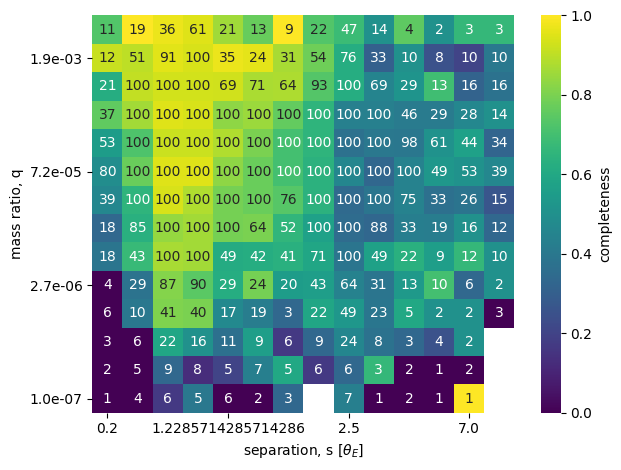

In [17]:
# event counts per s, q bin
heatmap_numerator = pd.crosstab(numerator["s_bin"], numerator["q_bin"]).T

# prep axis labels cause we boutta aesthetize
y_labels = q_bins[:-1]
x_labels = s_bins[:-1]

# plot heatmap
ax = sns.heatmap(
    heatmap_numerator/heatmap_data, annot=heatmap_data, fmt="d", cmap="viridis", xticklabels=False, yticklabels=False,
    cbar_kws={"label": "completeness"}
)
ax.invert_yaxis() 

# show every 4th tick, and place ticks at center of corresponding cells
x_ticks = np.arange(len(x_labels))[::4] + 0.5
y_ticks = np.arange(len(y_labels))[::4] + 0.5
ax.set_xticks(x_ticks)
ax.set_xticklabels([x_labels[int(i)] for i in np.arange(len(x_labels))[::4]])
ax.set_yticks(y_ticks)
ax.set_yticklabels([f"{y_labels[int(i)]:.1e}" for i in np.arange(len(y_labels))[::4]])

ax.set_xlabel(r"separation, s [$\theta_E$]")
ax.set_ylabel("mass ratio, q")
plt.tight_layout()
plt.savefig(root_dir+'/plots/completeness_1s2l.png')
plt.show()


### Modeling

In [18]:
def model(event_id, lc_data):

    lc_data['bjd-2450000'] = lc_data['bjd']-2450000
    
    # create event directory in the format RTModel wants
    event_data_me = 'event_data_chris'
    new_event_dir = root_dir + '/' + event_data_me + '/event_' + event_id
    try:
        os.mkdir(new_event_dir)
    except Exception as e:
        pass
    # create /Data/ directory in your event directory. This is necessary for RTModel, which is very picky about your event directory layout!
    try:
        os.mkdir(new_event_dir + '/Data/')
    except Exception as e:
        pass

    # set up filters
    for filt in filters:
        lc_data_filt = lc_data.loc[lc_data['filt']==filt]#[time_mask]
        lc_data_dat = pd.DataFrame({'Flux': lc_data_filt['flux_uJy'], 'err': lc_data_filt['flux_err_uJy'], 'HJD-2450000': lc_data_filt['bjd-2450000']})
        if filt=='F087':
            dat_filepath = new_event_dir + '/Data/RomanZ087sat2.dat'
        elif filt=='F146':
            dat_filepath = new_event_dir + '/Data/RomanW146sat1.dat'
        elif filt=='F213':
            dat_filepath = new_event_dir + '/Data/RomanK213sat3.dat'
        with open(dat_filepath, "w", encoding="utf-8") as f:
            f.write("# Flux err HJD-2450000\n")
            lc_data_dat.to_csv(f, sep=' ', header=None, index=False)

    # add coordinates in Data/ dir too     
    coords = SkyCoord(ra=lc_data_filt['ra_deg'].values[0]*u.degree, dec=lc_data_filt['dec_deg'].values[0]*u.degree, frame='icrs')
    ra_hms = coords.ra.to_string(unit=u.hourangle, sep=':', pad=True)
    dec_dms = coords.dec.to_string(sep=':', pad=True)
    coord_filepath = new_event_dir + '/Data/event.coordinates'
    with open(coord_filepath, "w", encoding="utf-8") as cf:
        cf.write(f"{ra_hms} {dec_dms}")

    # add limb darkening file in Data/
    limb_dark_filepath = new_event_dir + '/Data/LimbDarkening.txt'
    with open(limb_dark_filepath, "w", encoding="utf-8") as ld:
        ld.write("0.33 \n0.4532 \n0.251")

    # RTModel
    rtm = RTModel.RTModel(new_event_dir) # if I do rtm.run(), this argument is empty (spoiler: we're not doing rtm.run()
    rtm.set_satellite_dir(root_dir + '/satellitedir')
    #rtm.config_Reader(otherseasons=-1) # throw away all other seasons; this is reasonable because seasons are separated by ~half a year
    rtm.config_Reader(otherseasons=0, binning=1000000, renormalize=0) # there is a risk that long-duration events are more subject to parallax, which could affect planet recovery (slanty-->think it's a planet?)
    # rtm.config_InitCond(usesatellite = 1)
    rtm.config_InitCond(usesatellite = 1, peakthreshold=5) # usesatellite=1: space-based; usesatellite=0: ground-based; default peakthreshold is 10, but PIT uses 5, which is slower but better for recovery
    rtm.Reader()
    rtm.InitCond()

    rtm.run(root_dir + '/' + event_data_me + '/event_'+event_id)
    rtm.Finalizer()

    return
                    

I've stopped and restarted this run multiple times, so let's build in a way to easily get the bus moving again without redoing done events. 

In [29]:
event_data_me = 'event_data_chris/'
events_dir = root_dir + event_data_me
done_events = []
for f in tqdm(np.sort(glob.glob(events_dir+"/*"))):
    event_id = int(f.removeprefix(events_dir+"event_"))
    if event_id < 300000:
        continue

    event_dir = events_dir + 'event_' + "{:04d}/".format(event_id)

    if os.path.isdir(event_dir+'FinalModels/') == True:
        done_events.append(event_id)


100%|██████████| 217/217 [00:00<00:00, 17047.14it/s]


Run the thing

In [33]:
for n in numerator_event_ids:
    print(n)
    if n>306505:
        dafasdfadsf

306467
306479
306501
306505
306508


NameError: name 'dafasdfadsf' is not defined

In [30]:
len(numerator_event_ids), len(done_events), len(np.setdiff1d(numerator_event_ids, np.array(done_events)))

(5782, 21, 5769)

In [31]:
np.setdiff1d(numerator_event_ids, np.array(done_events))

array([306505, 306544, 306546, ..., 342084, 342087, 342091], shape=(5769,))

In [ ]:
filters = ['F087', 'F146', 'F213'] 
numerator_event_ids = np.sort(numerator['event_id'])
numerator_event_ids_not_done = np.setdiff1d(numerator_event_ids, np.array(done_events))
for numerator_event_id in numerator_event_ids_not_done: #numerator_event_ids:
    numerator_event_id = str(numerator_event_id)

    event_obs = con.execute(f"""
        SELECT 
            o.event_id,
            m.name,
            e.bjd,
            o.filt,
            o.flux_uJy,
            o.flux_err_uJy,
            m.tE_helio,
            m.sim_label,
            m.ra_deg,
            m.dec_deg
        FROM '{obs_p}' o
        JOIN '{epoch_p}' e ON o.epoch_id = e.epoch_id
        JOIN '{meta_p}' m ON o.event_id = m.event_id
        WHERE o.event_id = {numerator_event_id}
        ORDER BY e.bjd
    """).df()
    
    print(f"Event {event_id}: {event_obs['name'].iloc[0]} ({event_obs['sim_label'].iloc[0]})")

    model(numerator_event_id, event_obs)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Event 306584: RMDC26_306505 (RMDC26_1S2L_ML)
*********************
****   RTModel   ****
*********************
Event name: /teams/mldc-ipacpeople/event_data_chris/event_306505
Number of processors: 32
- Launching: Reader
  Pre-processing data...
  Found ground telescopes:  []
  Found satellite 1:  ['RomanW146sat1']
  Found satellite 2:  ['RomanZ087sat2']
  Found satellite 3:  ['RomanK213sat3']
  OK
- Launching: InitCond
  Setting initial conditions...
Peaks:  
11651.6400 [681.7918]
13117.4800 [5.9087]

  OK
o Wed Oct 28 21:29:04 2026
- Analyzing event:  /teams/mldc-ipacpeople/event_data_chris/event_306505
- Launching: Reader
  Pre-processing data...
  Found ground telescopes:  []
  Found satellite 1:  ['RomanW146sat1']
  Found satellite 2:  ['RomanZ087sat2']
  Found satellite 3:  ['RomanK213sat3']
  OK
o Wed Oct 28 21:29:04 2026
- Launching: InitCond
  Setting initial conditions...
Peaks:  
11651.6400 [681.7918]
13117.4800 [5.9087]

  OK
o Wed Oct 28 21:29:04 2026
- Single-lens-Single-